#Import libaries

In [4]:
import numpy as np # linear algebra
import pandas as pd # data processing
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator
import seaborn as sns
import plotly.express as px

%matplotlib inline

#Set DPI for figures

In [5]:
# Set DPI for fugures

plt.rcParams['figure.dpi'] = 300
plt.rcParams['savefig.dpi'] = 300

#Set defult font size in display

In [6]:

# Set the default font size and weight
plt.rcParams['font.size'] = 30
plt.rcParams['font.weight'] = 'bold'

#Drive Mount

In [1]:
# Drive connection

from google.colab import drive
drive.mount('/content/drive')
print("Drive Mount Successfully")

Mounted at /content/drive
Drive Mount Successfully


#Load Data from Drive

In [7]:


# Load X_train (DataFrame)
x_train = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/Thesis/X_train_SMOTENC.csv')

# Load y_train
y_train = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/Thesis/y_train_SMOTENC.csv')

# Load x_test (DataFrame)
x_test = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/Thesis/X_test.csv')

# Load y_test
y_test = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/Thesis/y_test.csv')


print("The Train data shape")
print(x_train.shape)
print(y_train.shape)

print("\nThe Train data shape")
print(x_test.shape)
print(y_test.shape)


The Train data shape
(370, 19)
(370, 1)

The Train data shape
(79, 19)
(79, 1)


In [8]:
# Shape of y_train
print("Shape:", y_train.shape)

# Count for each class
print("\nClass distribution:")
print(y_train.value_counts())

# Optional: percentage distribution
print("\nClass percentage:")
print(y_train.value_counts(normalize=True) * 100)

Shape: (370, 1)

Class distribution:
Status
0         185
1         185
Name: count, dtype: int64

Class percentage:
Status
0         50.0
1         50.0
Name: proportion, dtype: float64


#Counting values

In [9]:
# Count for each class in y_test
print("Class distribution:")
print(y_test.value_counts())

# Optional: percentage distribution
print("\nClass percentage:")
print(y_test.value_counts(normalize=True) * 100)

Class distribution:
Status
1         47
0         32
Name: count, dtype: int64

Class percentage:
Status
1         59.493671
0         40.506329
Name: proportion, dtype: float64


#Load Model (GradientBoosting)

In [11]:
import joblib

# Load the saved model
GBM = joblib.load('/content/drive/MyDrive/Colab Notebooks/Thesis/GradientBoosting.pkl')

print("Model loaded succesfully")

Model loaded succesfully


#SHAP

In [12]:
#installing shap
!pip install shap

In [13]:
#import shap
import shap

#Converting Numpy array

In [14]:
# Converting to numpy array

x_train_np = np.array(x_train)
x_test_np = np.array(x_test)

In [15]:
# Assign x_test column names to X_train
x_train.columns = x_test.columns

# Check
print(x_train.columns)

Index(['ID', 'N_Days', 'Drug', 'Age', 'Sex', 'Ascites', 'Hepatomegaly',
       'Spiders', 'Edema', 'Bilirubin', 'Cholesterol', 'Albumin', 'Copper',
       'Alk_Phos', 'SGOT', 'Tryglicerides', 'Platelets', 'Prothrombin',
       'Stage'],
      dtype='object')


In [16]:
# Get the list of features (columns)
feature_names_list = x_train.columns.tolist()

print(feature_names_list)

['ID', 'N_Days', 'Drug', 'Age', 'Sex', 'Ascites', 'Hepatomegaly', 'Spiders', 'Edema', 'Bilirubin', 'Cholesterol', 'Albumin', 'Copper', 'Alk_Phos', 'SGOT', 'Tryglicerides', 'Platelets', 'Prothrombin', 'Stage']


#Making shap values


In [17]:

# Define Shap Explainer
explainer = shap.TreeExplainer(GBM)

In [18]:

# Shap values
shap_values = explainer.shap_values(x_test_np)

In [19]:

# Save SHAP values
np.save(
    '/content/drive/MyDrive/Colab Notebooks/Thesis/shap_values_GBM.npy',
    shap_values
)


#Loading SHAP values

In [21]:
# Load SHAP values from the saved file
shap_values = np.load('/content/drive/MyDrive/Colab Notebooks/Thesis/shap_values_GBM.npy')

#Figure

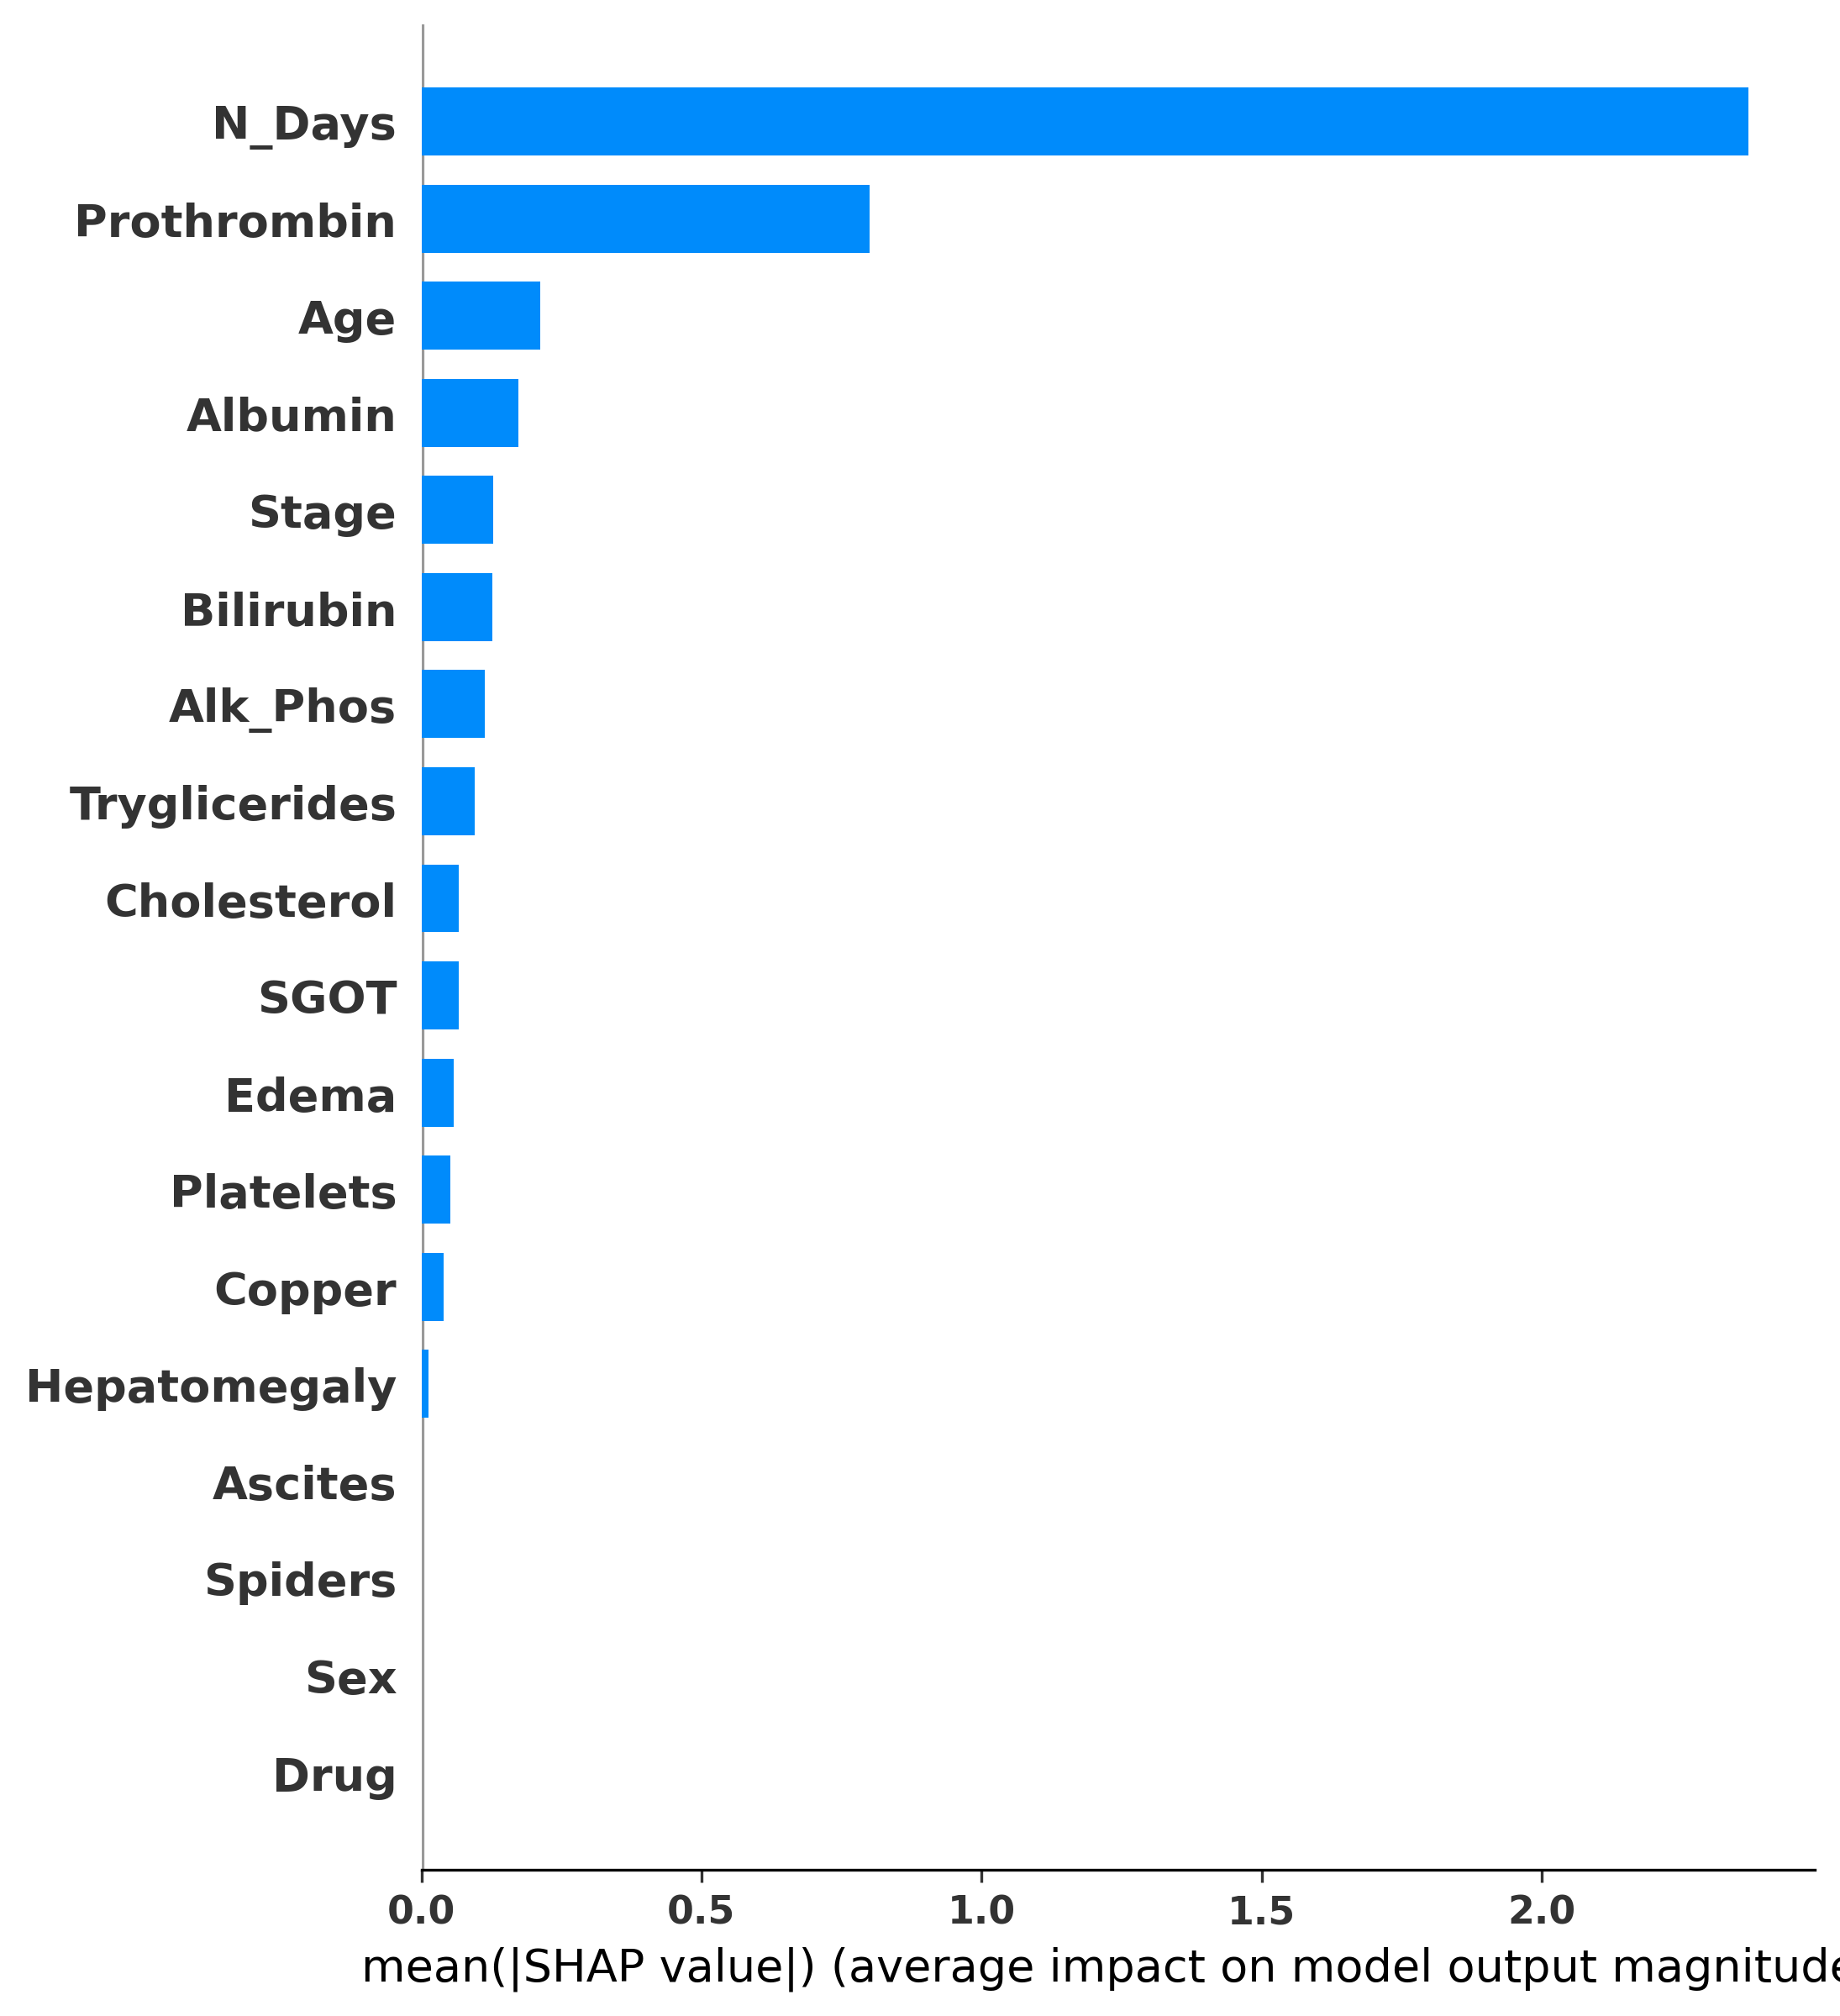

In [22]:
# Find index of ID column
status_index = x_test.columns.get_loc("ID")

# Remove ID SHAP values
shap_values_without_ID = np.delete(
    shap_values,
    status_index,
    axis=1
)

# Remove ID column from X_test
x_test_without_ID = x_test.drop(columns=["ID"])

# SHAP summary bar plot
shap.summary_plot(
    shap_values_without_ID,
    x_test_without_ID,
    plot_type="bar",
    max_display=19
)

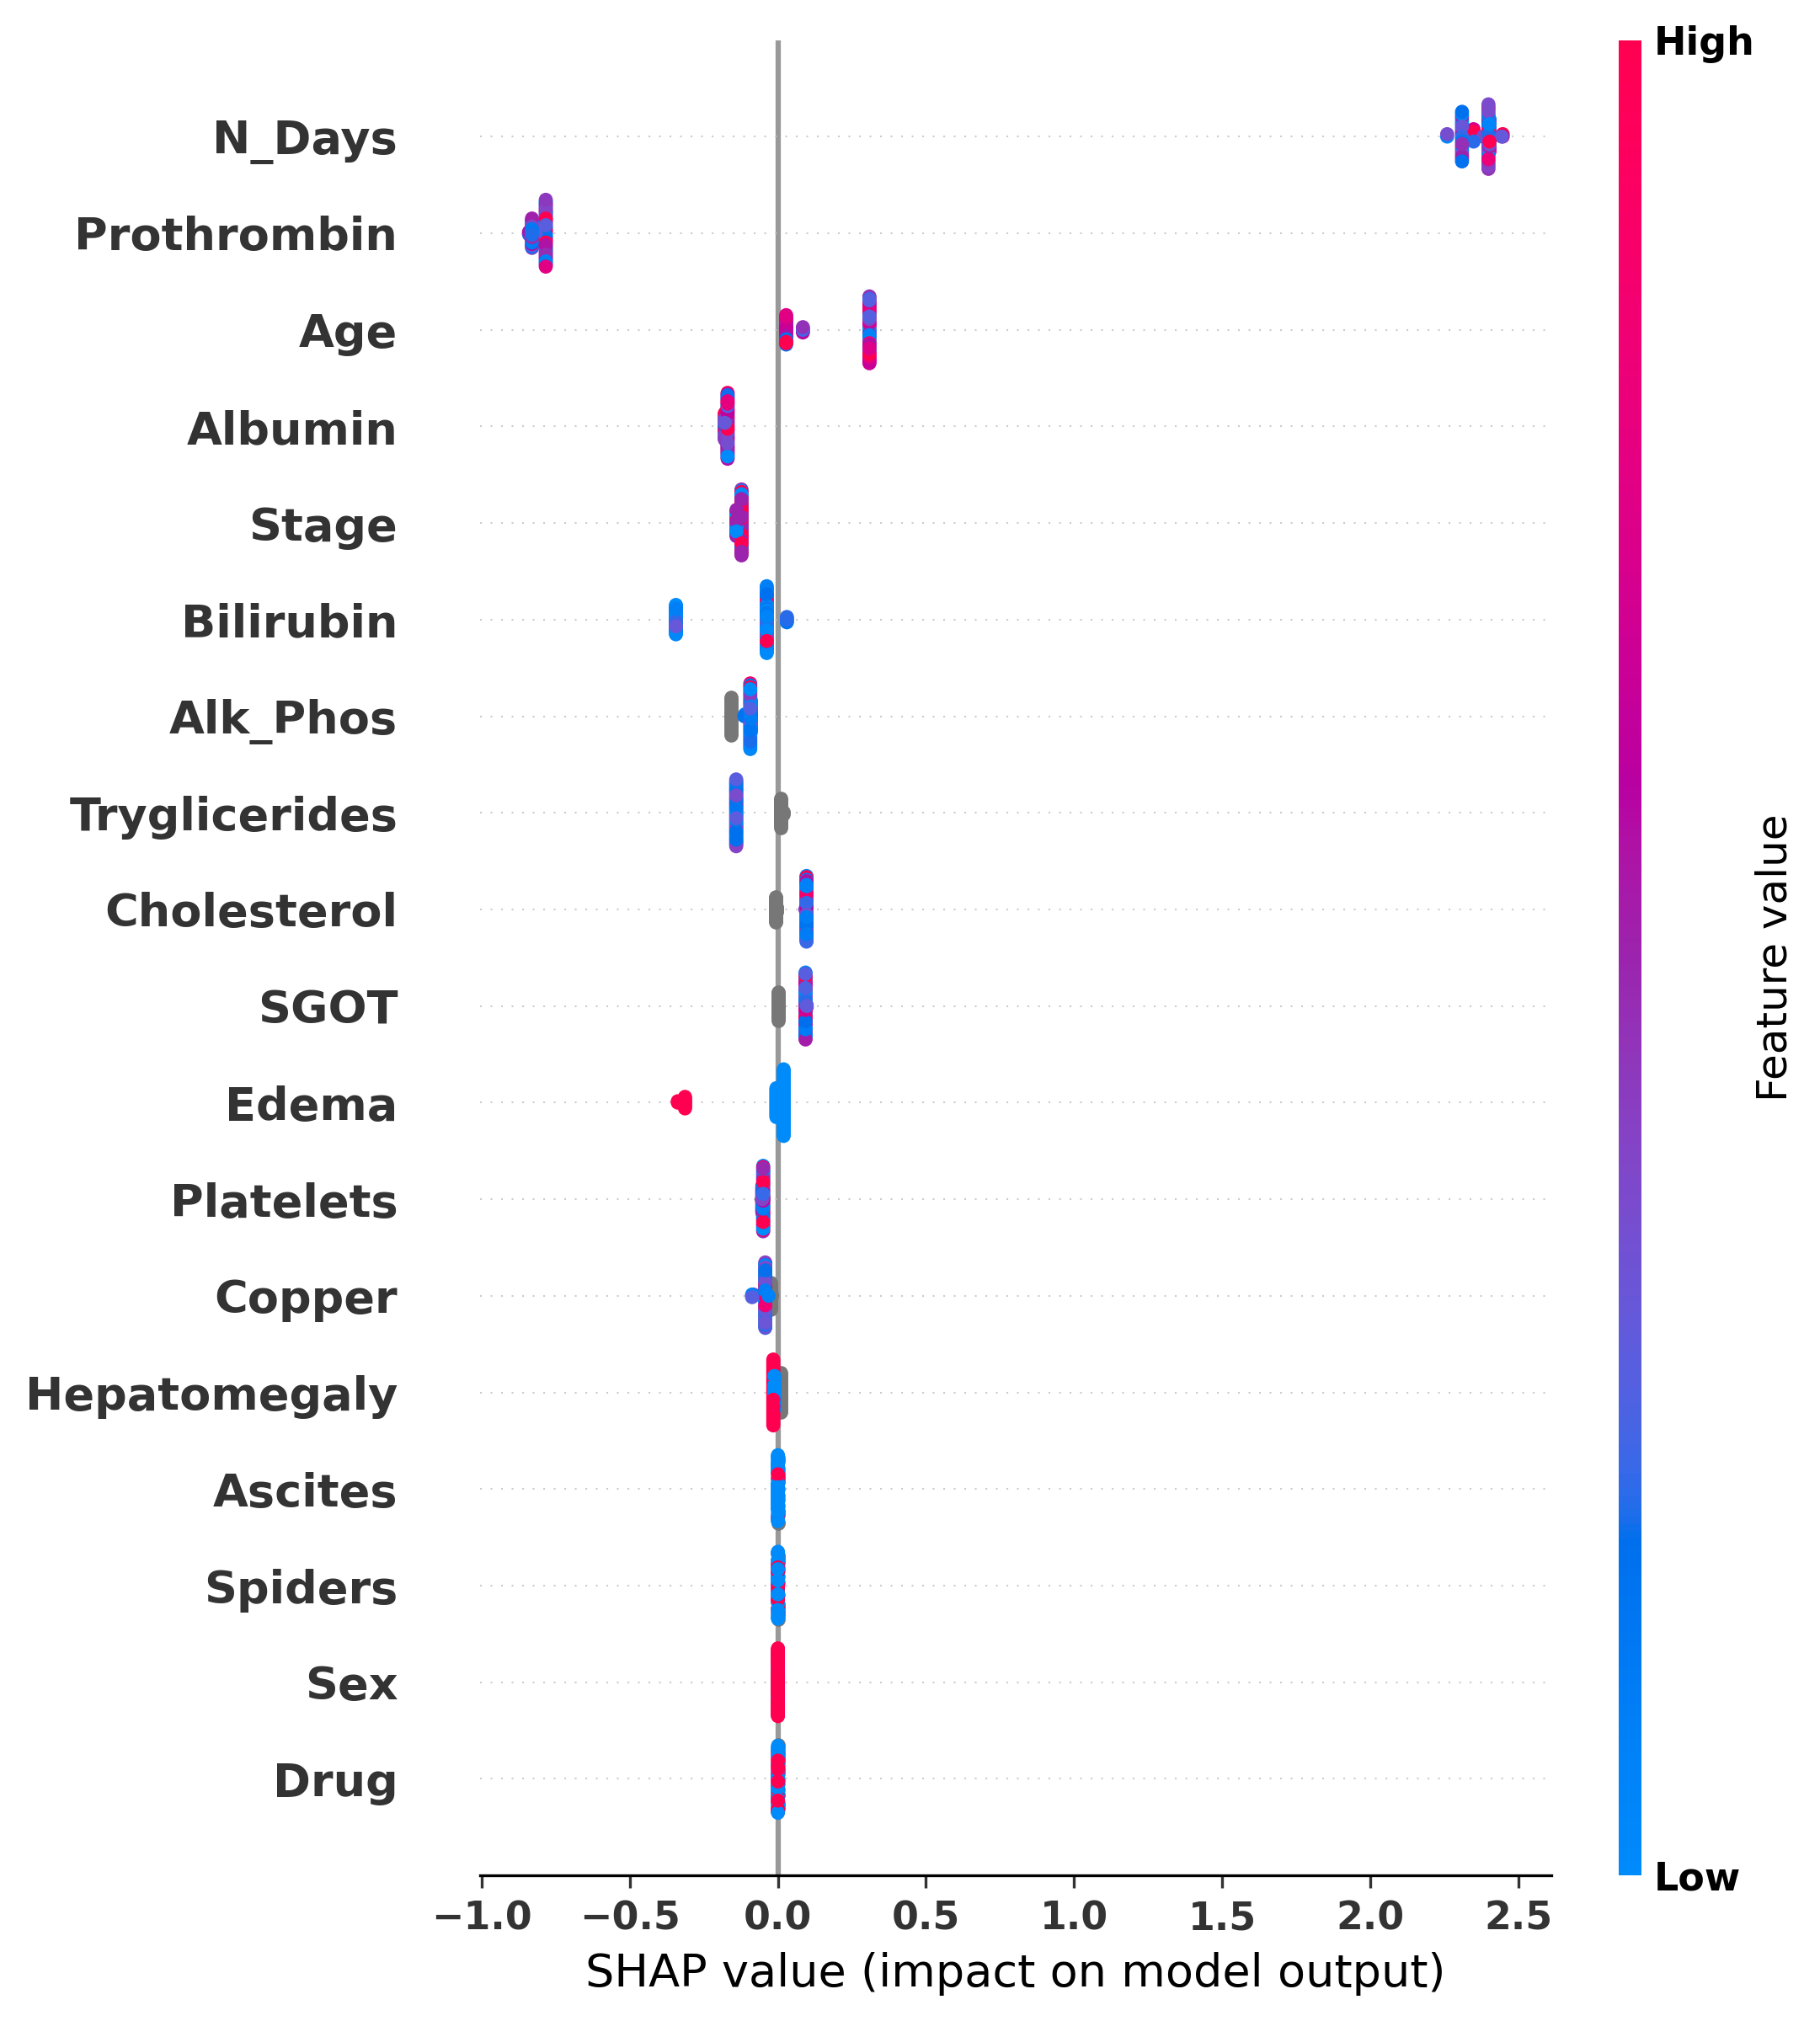

<Figure size 3000x2400 with 0 Axes>

In [23]:
# Find index of ID column
id_index = x_test.columns.get_loc("ID")

# Remove ID SHAP values
shap_values_without_ID = np.delete(
    shap_values,
    id_index,
    axis=1
)

# Remove ID column from X_test
x_test_without_ID = x_test.drop(columns=["ID"])

# Set max number of displayed features
max_display = 19

# Create SHAP summary plot
shap.summary_plot(
    shap_values_without_ID,
    x_test_without_ID,
    max_display=max_display
)

# Get current figure
fig = plt.gcf()

# Optional: adjust figure size
fig.set_size_inches(10, 8)

# Show plot
plt.show()

In [24]:
x_train.columns = x_train.columns.astype(str)
x_test.columns = x_test.columns.astype(str)

In [25]:
binary_cols = []
categorical_cols = []
continuous_cols = []

for col in x_train.columns:

    series = x_train[col]
    n_unique = series.nunique(dropna=True)

    print(f"{col:30} | Unique: {n_unique:3} | Dtype: {series.dtype}")

    # Binary
    if set(series.dropna().unique()).issubset({0, 1}):
        binary_cols.append(col)

    # Likely categorical
    elif n_unique <= 10:
        categorical_cols.append(col)

    # Likely continuous
    else:
        continuous_cols.append(col)


ID                             | Unique: 370 | Dtype: float64
N_Days                         | Unique: 357 | Dtype: float64
Drug                           | Unique:  19 | Dtype: float64
Age                            | Unique: 326 | Dtype: float64
Sex                            | Unique:   7 | Dtype: float64
Ascites                        | Unique:   3 | Dtype: float64
Hepatomegaly                   | Unique:  16 | Dtype: float64
Spiders                        | Unique:   7 | Dtype: float64
Edema                          | Unique:  14 | Dtype: float64
Bilirubin                      | Unique: 138 | Dtype: float64
Cholesterol                    | Unique: 206 | Dtype: float64
Albumin                        | Unique: 189 | Dtype: float64
Copper                         | Unique: 181 | Dtype: float64
Alk_Phos                       | Unique: 274 | Dtype: float64
SGOT                           | Unique: 200 | Dtype: float64
Tryglicerides                  | Unique: 172 | Dtype: float64
Platelet

In [26]:
print("\nBinary Columns:")
print(binary_cols)






Binary Columns:
[]


In [27]:
print("\nCategorical/Multiclass Columns:")
print(categorical_cols)


Categorical/Multiclass Columns:
['Sex', 'Ascites', 'Spiders']


In [28]:
print("\nContinuous Numeric Columns:")
print(continuous_cols)


Continuous Numeric Columns:
['ID', 'N_Days', 'Drug', 'Age', 'Hepatomegaly', 'Edema', 'Bilirubin', 'Cholesterol', 'Albumin', 'Copper', 'Alk_Phos', 'SGOT', 'Tryglicerides', 'Platelets', 'Prothrombin', 'Stage']
